# Importing libraries

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-Learn tools for building the pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Preprocessing tools
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Machine Learning Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [13]:
# 1. Load the clean data
#df = pd.read_csv('cleaned_taxi_data.csv')
df = pd.read_csv('final_internship_data.csv')

# 2. Separate your features (X) from the target you want to predict (y)
X = df.drop(columns=['fare_amount'])
y = df['fare_amount']

# 3. Perform the Train/Test split BEFORE building the pipeline to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# handling missing values

In [14]:
# Calculate the percentage of missing values per column
missing_pct = X_train.isnull().mean() * 100

# Display only the columns that actually have missing data
print("Percentage of missing values:")
print(missing_pct[missing_pct > 0])

Percentage of missing values:
dropoff_longitude    0.00125
dropoff_latitude     0.00125
jfk_dist             0.00125
ewr_dist             0.00125
lga_dist             0.00125
sol_dist             0.00125
nyc_dist             0.00125
distance             0.00125
bearing              0.00125
dtype: float64


In [15]:
# 1. Align X_train and y_train, drop missing rows, and re-separate
train_combined = pd.concat([X_train, y_train], axis=1).dropna()
X_train = train_combined.drop(columns=['fare_amount'])
y_train = train_combined['fare_amount']

# 2. Repeat for the test set to ensure consistency
test_combined = pd.concat([X_test, y_test], axis=1).dropna()
X_test = test_combined.drop(columns=['fare_amount'])
y_test = test_combined['fare_amount']

# 3. Drop the raw datetime string column since temporal features are already extracted
X_train = X_train.drop(columns=['pickup_datetime'])
X_test = X_test.drop(columns=['pickup_datetime'])

# Verify no missing values remain
print(f"Remaining missing in X_train: {X_train.isnull().sum().sum()}")
print(f"Remaining missing in X_test: {X_test.isnull().sum().sum()}")

Remaining missing in X_train: 0
Remaining missing in X_test: 0


**missingness of 0.00125%; because this is well below the 2-3% threshold and appears random, I dropped these rows using dropna() to avoid introducing noise via imputation**

# Handling duplicate values

In [16]:
# Check for exact identical rows
duplicate_count = X_train.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicate_count}")

Number of exact duplicate rows: 0


# Encoding Categorical Variables and feature scaling

In [17]:
X_train.dtypes

User ID                  str
User Name                str
Driver Name              str
Car Condition            str
Weather                  str
Traffic Condition        str
key                      str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
hour                   int64
day                    int64
month                  int64
weekday                int64
year                   int64
jfk_dist             float64
ewr_dist             float64
lga_dist             float64
sol_dist             float64
nyc_dist             float64
distance             float64
bearing              float64
dtype: object

In [18]:
# 1. Define feature groupings
categorical_features = ['weekday', 'month']
numeric_features = [col for col in X_train.columns if col not in categorical_features]

# 2. Build the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        # Step 4: Scale numeric features for linear models
        ('num', StandardScaler(), numeric_features),
        
        # Step 3: One-hot encode low-cardinality nominal features
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

# Optional: View the pipeline visually in your Jupyter Notebook
from sklearn import set_config
set_config(display="diagram")
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

- Step4: I applied One-Hot Encoding to the weekday and month features because they are low-cardinality nominal variables with no natural mathematical order, avoiding the creation of a false hierarchy.
- Step5: I used StandardScaler for the continuous numerical features (distances, coordinates, and passenger counts) to ensure gradient descent converges evenly for the Linear Regression model, while deliberately keeping the one-hot encoded columns out of the scaler to avoid adding noise to their binary values.

# Feature extraction

In [19]:
import numpy as np

# Safely apply to X_train
if 'hour' in X_train.columns:
    X_train['hour_sin'] = np.sin(2 * np.pi * X_train['hour'] / 24)
    X_train['hour_cos'] = np.cos(2 * np.pi * X_train['hour'] / 24)
    X_train = X_train.drop(columns=['hour'], errors='ignore')

# Safely apply to X_test
if 'hour' in X_test.columns:
    X_test['hour_sin'] = np.sin(2 * np.pi * X_test['hour'] / 24)
    X_test['hour_cos'] = np.cos(2 * np.pi * X_test['hour'] / 24)
    X_test = X_test.drop(columns=['hour'], errors='ignore')

print("Success! Cyclical features added.")
print(X_train[['hour_sin', 'hour_cos']].head())

Success! Cyclical features added.
        hour_sin      hour_cos
269056 -1.000000 -1.836970e-16
499174 -0.866025 -5.000000e-01
85143   0.707107 -7.071068e-01
260335  0.500000  8.660254e-01
338124 -0.258819 -9.659258e-01


In [20]:
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso

# 1. Drop the useless EDA columns and text IDs that snuck back in
cols_to_drop = ['User ID', 'User Name', 'Driver Name', 'Car Condition', 'Weather', 'Traffic Condition', 'key']
X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')

# 2. Define feature groupings for Steps 3 & 4
categorical_features = ['weekday', 'month']
numeric_features = [col for col in X_train.columns if col not in categorical_features]

# 3. Build the ColumnTransformer (Encoding & Scaling)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# 4. Step 6: Define the Feature Selector (Lasso shrinks weak coefficients to 0)
feature_selector = SelectFromModel(Lasso(alpha=0.01, random_state=42))

# 5. Assemble the Final Pipelines!
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('selector', feature_selector),
    ('model', LinearRegression())
])

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('selector', feature_selector),
    ('model', RandomForestRegressor(random_state=42))
])

# View the pipeline visually
from sklearn import set_config
set_config(display="diagram")
display(lr_pipeline)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0

**To prevent optimistic bias and data leakage, I implemented an embedded feature selection method using SelectFromModel with a Lasso estimator directly inside the Pipeline; this ensures features are selected dynamically within each cross-validation fold rather than globally on the training set.**

# Outliers detection and treatment

C:\Users\Asus - TYF\AppData\Local\Temp\ipykernel_75936\2750039258.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(y_train, vert=False)


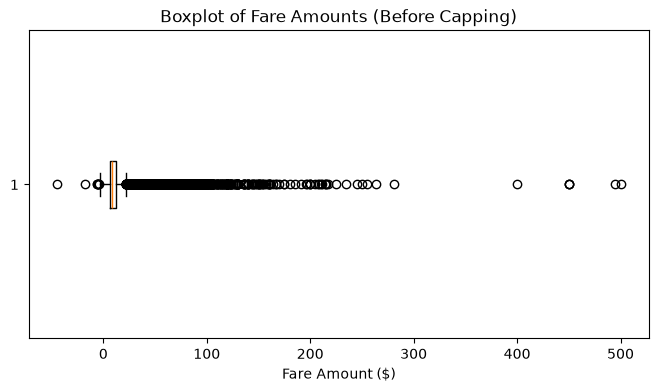

C:\Users\Asus - TYF\AppData\Local\Temp\ipykernel_75936\2750039258.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(y_train_capped, vert=False)


99th Percentile of fare_amount: $52.30


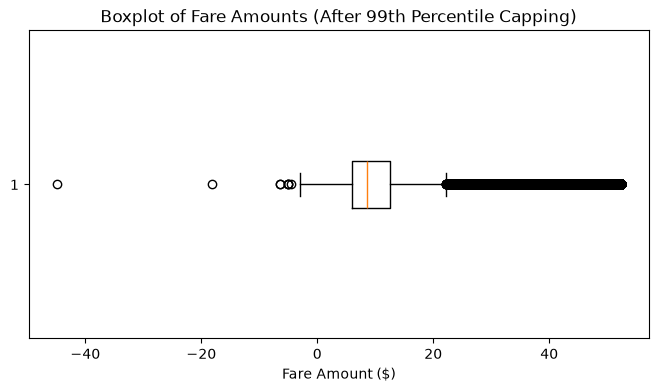

In [21]:
# 1. Visualize the outliers before treatment
plt.figure(figsize=(8, 4))
plt.boxplot(y_train, vert=False)
plt.title("Boxplot of Fare Amounts (Before Capping)")
plt.xlabel("Fare Amount ($)")
plt.show()

# 2. Calculate the 99th percentile threshold on the training data
cap_threshold = np.percentile(y_train, 99)
print(f"99th Percentile of fare_amount: ${cap_threshold:.2f}")

# 3. Cap (Winsorize) the extreme values in the training set
# np.where(condition, value_if_true, value_if_false)
y_train_capped = np.where(y_train > cap_threshold, cap_threshold, y_train)

# Visualize after capping to see the difference
plt.figure(figsize=(8, 4))
plt.boxplot(y_train_capped, vert=False)
plt.title("Boxplot of Fare Amounts (After 99th Percentile Capping)")
plt.xlabel("Fare Amount ($)")
plt.show()

**Because extreme taxi fares represent valid rare events rather than data entry errors, I chose to cap (winsorize) the fare_amount training target at the 99th percentile instead of deleting the rows; this prevents the MSE loss function from being disproportionately skewed by extreme values while safely keeping those records in the dataset.**

# CROSS VALIDATION, HYPERPARAMETER TUNING

In [22]:
import joblib
import numpy as np
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Step 9: Define Cross-Validation strategy
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Train the Baseline Model (Linear Regression)
print("Training Baseline Linear Regression...")
lr_pipeline.fit(X_train, y_train_capped) # Notice we train on the capped target!
y_pred_baseline = lr_pipeline.predict(X_test)

# 3. Step 10: Hyperparameter Tuning (Random Forest)
print("Tuning Random Forest via RandomizedSearchCV (this may take a minute)...")
param_distributions = {
    'model__n_estimators': [50, 100, 150],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5, 10]
}

rf_random = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_distributions,
    n_iter=5, # Tests 5 random combinations to keep it fast
    cv=kf,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train, y_train_capped)
best_rf_pipeline = rf_random.best_estimator_
y_pred_tuned = best_rf_pipeline.predict(X_test)

# 4. Deliverable: Results Table on the Held-Out Test Set
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name: <28} | MAE: {mae:<6.2f} | RMSE: {rmse:<6.2f} | R2: {r2:<6.4f}")

print("\n--- FINAL RESULTS ON HELD-OUT TEST SET ---")
evaluate_model(y_test, y_pred_baseline, "Baseline (Linear Regression)")
evaluate_model(y_test, y_pred_tuned, "Tuned (Random Forest)")

# 5. Deliverable: Save the final best pipeline
joblib.dump(best_rf_pipeline, 'final_model_pipeline.joblib')
print("\nFinal pipeline successfully saved to 'final_model_pipeline.joblib'")

Training Baseline Linear Regression...
Tuning Random Forest via RandomizedSearchCV (this may take a minute)...

--- FINAL RESULTS ON HELD-OUT TEST SET ---
Baseline (Linear Regression) | MAE: 5.94   | RMSE: 9.79   | R2: 0.0148
Tuned (Random Forest)        | MAE: 1.91   | RMSE: 4.70   | R2: 0.7728

Final pipeline successfully saved to 'final_model_pipeline.joblib'
